# Document clustering | Hierarchical methods

Compare Ward/Euclidean and complete-linkage/cosine clustering on normalized reduced text representations. Review separation metrics, metadata composition, prominent vocabulary, and examples that do not resemble their cluster centers.

The experiments retain their original linkage and clustering parameters. Performance numbers must come from a successful local run; the attached notebooks contain no saved metric outputs.


## Prepare hierarchical-clustering dependencies

Load the same text preprocessing and matrix construction libraries used for the clustering comparison.


In [1]:
# Import text-feature, clustering and validation dependencies.

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from scipy.sparse import hstack, csr_matrix
from sklearn.cluster import HDBSCAN

from sklearn.cluster import KMeans
from sklearn.metrics import make_scorer, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk.corpus import stopwords
from nltk import pos_tag
from spacy.lang.en.stop_words import STOP_WORDS as SPACY_STOP_WORDS

from mpl_toolkits.mplot3d import Axes3D 

import gensim
from gensim.models import Word2Vec

import warnings
warnings.filterwarnings('ignore')

nltk.data.path.append("./data")
nltk.download('punkt', download_dir="./data")
nltk.download("punkt_tab", download_dir="./data")
nltk.download("averaged_perceptron_tagger", download_dir="./data")
nltk.download("averaged_perceptron_tagger_eng", download_dir="./data")
nltk.download('stopwords', download_dir="./data")
nltk.download('wordnet', download_dir="./data")



[nltk_data] Downloading package punkt to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package punkt_tab to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable

False

## Read the article corpus

Load the renamed article dataset, remove missing bodies, and include headlines in the text passed into the vectorizer.


In [2]:
# Load and filter the source documents before constructing text features.


df = pd.read_csv("./data/youth_information_articles.csv", encoding='utf-8-sig')


df['article_title'] = df['article_title'].fillna('').astype(str)



df = df[df['article_body'] != 'N/A']
df = df.dropna(subset=['article_body'])



df['article_body'] = df['article_title'] + " " + df['article_body']

## Normalize the corpus text

Apply the original POS-assisted lemmatization and the same domain stopwords as the K-Means notebook.


In [3]:
# Apply the original article normalization and stopword filtering rules.







def wordnet_tag_from_treebank(treebank_tag):
    """
    Convert Penn Treebank tags into the part-of-speech codes used by WordNet.
    """
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        
        return wordnet.NOUN


lemmatizer = WordNetLemmatizer()






stop_words = set(SPACY_STOP_WORDS)



domain_stopwords = [
    
    'spunout', 'spun', 'out', 'ie', 'ireland', 'irish', 'www', 'http', 'https', 'com', 
    'copyright', 'privacy', 'policy', 'terms', 'conditions', 'login', 'sign', 'register',
    
    
    'page', 'section', 'footer', 'header', 'sidebar', 'widget', 'nav', 'advertisement', 'ad',
    'promo', 'cookie', 'script', 'javascript', 'css', 'html', 'body', 'main', 'published', 'updated',
    'author', 'post', 'article', 'url', 'permalink',
    
    
    
    'day', 'new', 'good', 'bad',
    'check', 'try', 'keep',
    'like', 'just', 'get', 'also', 'would', 'could', 'one', 'make', 'use', 'way', 'well', 
    'time', 'know', 'need', 'really', 'thing', 'think', 'much', 'even', 'still', 'another', 
    'every', 'go', 'want', 'take', 'find', 'look', 'come', 'year', 'old', 'may', 'might',
    
    
    'click', 'read', 'link', 'menu', 'comment', 'reply',
    
    
    'u', 'ur', 'im', 'dont', 'cant', 'wont', 'oh', 'ok', 'please', 'thanks', 'thank', 'yes', 'no'
]


stop_words.update(domain_stopwords)


def normalize_article_text(text):
    """
    Refined text cleaning function.
    Includes explicit removal of separator artifacts (e.g., ___, ///), 
    Normalize text by removing markup and irrelevant tokens, then lemmatize with POS information.
    """
    
    text = str(text).lower()
    
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', ' ', text)
    
    
    
    text = re.sub(r'[\_\-\.]{1,}', ' ', text)
    
    text = re.sub(r'[/\\]', ' ', text)

    
    text = re.sub(r"\'", "", text)
    
    
    
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    
    
    text = re.sub(r'\s+[a-z]\s+', ' ', text)
    
    
    words = text.split()
    
    
    
    
    tagged_words = pos_tag(words)
    
    
    lemmatized_words = []
    for word, tag in tagged_words:
        
        wn_tag = wordnet_tag_from_treebank(tag)
        
        
        
        lemma = lemmatizer.lemmatize(word, pos=wn_tag)
        lemmatized_words.append(lemma)
    
    
    
    filtered_words = [word for word in lemmatized_words if word not in stop_words and len(word) > 2]
    
    return " ".join(filtered_words)

## Prepare text and reference metadata

Compute normalized text and retain source sections and topics for descriptive analysis after clustering.


In [4]:
# Prepare normalized text and metadata series for interpretation after fitting.




print("Applying Text Cleaning (POS + Lemmatization)...")
df['normalized_text'] = df['article_body'].apply(normalize_article_text)




X_raw = df['article_body']
X = df['normalized_text']

y = df['source_section']
t = df['source_topic']

Applying Text Cleaning (POS + Lemmatization)...


## Vectorize with TF-IDF

Retain the existing TF-IDF feature limits, n-grams, document-frequency cutoffs and term-weight scaling.


In [5]:
# Build the configured TF-IDF matrix from the normalized corpus.


print("Vectorizing with TF-IDF...")




tfidf_vectorizer = TfidfVectorizer(
    
    max_features=20000,           
    
    
    
    ngram_range=(1, 3),
    
    
    
    min_df=3,                     
    
    
    max_df=0.7,                    
    
    
    sublinear_tf=True,            
    
    
    norm='l2'                     
)


X_tfidf_matrix = tfidf_vectorizer.fit_transform(X)

print(f"TF-IDF Shape: {X_tfidf_matrix.shape}")

Vectorizing with TF-IDF...
TF-IDF Shape: (2973, 20000)


## Calculate reduced document vectors

Use the existing variance-threshold selection and truncated SVD projection.


In [6]:
# Use truncated SVD to preserve the selected level of explained variance.

def choose_svd_component_count(X, variance_threshold=0.90, max_components=5000):
    """
    Finds the smallest number of components (K) that explains 
    a specific percentage of the variance in the data.
    """
    n_samples, n_features = X.shape
    
    
    
    search_limit = min(n_samples, max_components, n_features)
    
    print(f"Analyzing variance for up to {search_limit} components...")
    
    
    svd_analyzer = TruncatedSVD(n_components=search_limit, random_state=42)
    svd_analyzer.fit(X)
    
    
    
    explained_variance_ratio = svd_analyzer.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance_ratio)
    
    
    
    k_indices = np.where(cumulative_variance >= variance_threshold)[0]
    
    if len(k_indices) > 0:
        optimal_k = k_indices[0] + 1
        variance_acquired = cumulative_variance[optimal_k - 1]
    else:
        
        optimal_k = search_limit
        variance_acquired = cumulative_variance[-1]
        print(f"Warning: Threshold {variance_threshold*100}% not reached within {search_limit} components.")


    print(f"Target Variance:   {variance_threshold*100}%")
    print(f"Optimal K found:   {optimal_k}")
    print(f"Actual Variance:   {variance_acquired:.4f} ({variance_acquired*100:.2f}%)")

    
    return optimal_k





best_k = choose_svd_component_count(X_tfidf_matrix, variance_threshold=0.90)


print(f"\nApplying TruncatedSVD with K={best_k}...")
svd_final = TruncatedSVD(n_components=best_k, random_state=42)

X_tfidf_reduced_matrix = svd_final.fit_transform(X_tfidf_matrix)

print(f"Final Reduced Matrix Shape: {X_tfidf_reduced_matrix.shape}")

Analyzing variance for up to 2973 components...
Target Variance:   90.0%
Optimal K found:   1988
Actual Variance:   0.9001 (90.01%)

Applying TruncatedSVD with K=1988...
Final Reduced Matrix Shape: (2973, 1988)


**How to interpret this step.** This helps make hierarchical clustering more tractable, but the result depends on the number of retained components.


## Normalize document vectors

Rescale reduced vectors to unit length before hierarchical clustering.


In [7]:
# Rescale document vectors to unit length prior to hierarchical clustering.

from sklearn.preprocessing import Normalizer




normalizer = Normalizer()
X_tfidf_matrix_normalized = normalizer.fit_transform(X_tfidf_reduced_matrix)

print("\nData normalized for Spherical K-Means...")


Data normalized for Spherical K-Means...


## Compare Ward linkage across cluster counts

Compute silhouette and Davies–Bouldin scores for Ward linkage under Euclidean distance.


Evaluating Agglomerative Clustering from K=2 to K=10...

K=2: Davies-Bouldin=7.3744 | Silhouette=0.0041
K=3: Davies-Bouldin=7.1887 | Silhouette=0.0064
K=4: Davies-Bouldin=6.2773 | Silhouette=0.0097
K=5: Davies-Bouldin=5.4336 | Silhouette=0.0069
K=6: Davies-Bouldin=5.0490 | Silhouette=0.0060
K=7: Davies-Bouldin=4.5357 | Silhouette=0.0091
K=8: Davies-Bouldin=5.1984 | Silhouette=0.0108
K=9: Davies-Bouldin=5.0060 | Silhouette=0.0128

Plot successfully saved to: ./images/agglomerative_clustering_clusters_dbouldin_silhouette_euclidean.png


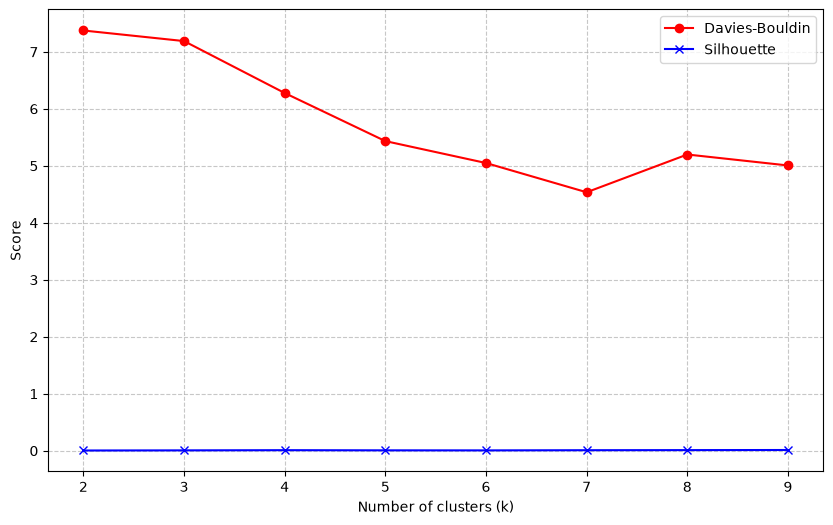

In [8]:
# Compare Ward linkage across the original candidate cluster counts.

import os
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt


db_scores = []
sil_scores = []


X_data = X_tfidf_matrix_normalized.copy()

print("Evaluating Agglomerative Clustering from K=2 to K=10...\n")

for k in range(2, 10):
    
    agg = AgglomerativeClustering(
        n_clusters=k,
        metric='euclidean',
        linkage='ward'    
    )
    
    
    labels = agg.fit_predict(X_data)
    
    
    db_index = davies_bouldin_score(X_data, labels)
    sil_score = silhouette_score(X_data, labels)
    
    db_scores.append(db_index)
    sil_scores.append(sil_score)

    print(f"K={k}: Davies-Bouldin={db_index:.4f} | Silhouette={sil_score:.4f}")


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(range(2, 10), db_scores, marker='o', label='Davies-Bouldin', color='red')
ax.plot(range(2, 10), sil_scores, marker='x', label='Silhouette', color='blue')

ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Score')

ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)


folder_name = "./images/"
file_name = "agglomerative_clustering_clusters_dbouldin_silhouette_euclidean.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

**How to interpret this step.** Ward linkage minimizes within-cluster dispersion under Euclidean geometry; compare both metrics before selecting a count.


## Compare complete linkage with cosine distance

Repeat the internal-score comparison using cosine distance and complete linkage.


Evaluating Agglomerative Clustering from K=2 to K=10...

K=2: Davies-Bouldin=19.6655 | Silhouette=0.0032
K=3: Davies-Bouldin=16.8530 | Silhouette=0.0029
K=4: Davies-Bouldin=14.4123 | Silhouette=0.0027
K=5: Davies-Bouldin=12.3145 | Silhouette=0.0044
K=6: Davies-Bouldin=11.5590 | Silhouette=0.0045
K=7: Davies-Bouldin=10.5414 | Silhouette=0.0047
K=8: Davies-Bouldin=10.2789 | Silhouette=0.0044
K=9: Davies-Bouldin=9.5509 | Silhouette=0.0068

Plot successfully saved to: ./images/agglomerative_clustering_clusters_dbouldin_silhouette_cosine.png


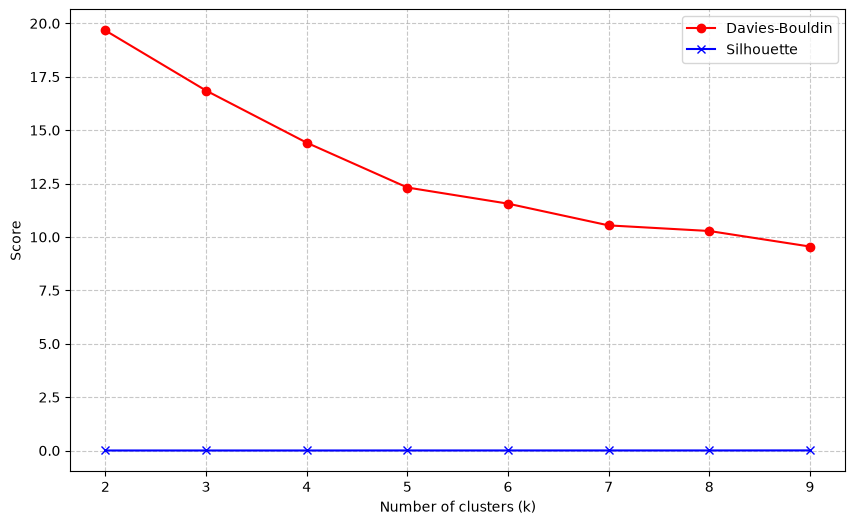

In [9]:
# Compare cosine-distance complete linkage with the same evaluation metrics.

import os
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt


db_scores = []
sil_scores = []


X_data = X_tfidf_matrix_normalized.copy()

print("Evaluating Agglomerative Clustering from K=2 to K=10...\n")

for k in range(2, 10):
    
    agg = AgglomerativeClustering(
        n_clusters=k,
        metric='cosine',
        linkage='complete'    
    )
    
    
    labels = agg.fit_predict(X_data)
    
    
    db_index = davies_bouldin_score(X_data, labels)
    sil_score = silhouette_score(X_data, labels)
    
    db_scores.append(db_index)
    sil_scores.append(sil_score)

    print(f"K={k}: Davies-Bouldin={db_index:.4f} | Silhouette={sil_score:.4f}")


fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(range(2, 10), db_scores, marker='o', label='Davies-Bouldin', color='red')
ax.plot(range(2, 10), sil_scores, marker='x', label='Silhouette', color='blue')

ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Score')

ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)


folder_name = "./images/"
file_name = "agglomerative_clustering_clusters_dbouldin_silhouette_cosine.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()


**How to interpret this step.** The two linkage methods optimize different notions of proximity; comparing the curves can expose sensitivity to distance choice.


## Evaluate hierarchical-clustering configurations

Keep the original configuration search over distance storage and tree construction options.


In [10]:
# Retain the original hierarchical parameter search and its documented scorer limitation.


agg = AgglomerativeClustering(
    n_clusters=7,
    metric='euclidean',
    linkage='ward'    
)

param_grid = {
    
    
    
    
    'compute_distances': [False, True],
    
    
    
    
    
    
    'compute_full_tree': ['auto', True]
}




print("Running Grid Search for Agglomerative Clustering...")
print("Note: This method merges all data (no noise) but can be slower on large datasets.")

agg_grid_search = GridSearchCV(
    agg, 
    param_grid=param_grid, 
    scoring=make_scorer(silhouette_score),
    cv=3,         
    n_jobs=-1,    
    verbose=1
)


agg_grid_search.fit(X_tfidf_matrix_normalized)

print("\nBest Parameters Found:")
print(agg_grid_search.best_params_)

Running Grid Search for Agglomerative Clustering...
Note: This method merges all data (no noise) but can be slower on large datasets.
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Best Parameters Found:
{'compute_distances': False, 'compute_full_tree': 'auto'}


**How to interpret this step.** The supplied GridSearchCV silhouette scorer is incompatible with unsupervised estimators as written; the project retains this limitation without changing the intended configuration.


## Summarize clusters by source section

Match hierarchical cluster IDs with the source section labels for interpretation.


In [11]:
# Summarize source-section composition within the fitted hierarchy.


best_agg = agg_grid_search.best_estimator_


agg_results_df = pd.DataFrame(X_tfidf_matrix_normalized)


agg_results_df['cluster_label'] = best_agg.labels_


agg_results_df['true_label'] = y


print("\nCluster Composition:")
print(agg_results_df.groupby('cluster_label')['true_label'].value_counts().to_string())


Cluster Composition:
cluster_label  true_label       
0              Voices               1019
               News                  480
               Health                217
               Life                  123
               Sex_Relationships      58
               Mental_Health          31
               Education              26
               Lgbti                  23
               Employment             19
1              Employment             94
               Life                   86
               Education              28
               Voices                 25
               News                   20
               Mental_Health           6
               Health                  2
2              Voices                242
               Mental_Health         175
               Life                   47
               Health                 21
               Sex_Relationships      19
               News                   16
               Lgbti                  11
  

**How to interpret this step.** These labels describe article provenance; they were not used to fit the hierarchy.


## Inspect topic composition within clusters

Group the predicted clusters with section and topic metadata to review concentration and overlap.


In [12]:
# Review source-topic frequencies within each cluster.


best_agg = agg_grid_search.best_estimator_


agg_results_df = pd.DataFrame(X_tfidf_matrix_normalized)


agg_results_df['cluster_label'] = best_agg.labels_


agg_results_df['true_label'] = y

agg_results_df['topics'] = t


composition = agg_results_df.groupby(['cluster_label', 'true_label', 'topics']).size()

print("\nDetailed Cluster Composition (Cluster > Category > Topic):")
print(composition.to_string())


Detailed Cluster Composition (Cluster > Category > Topic):
cluster_label  true_label         topics                        
0              Education          College                             3
                                  Finance                             6
                                  Leaving_Cert_Cao                    6
                                  School                              4
                                  Study_Exams                         7
               Employment         Apply_Job                           3
                                  Interviews                          2
                                  Job_Skills                          4
                                  Schemes                             1
                                  Unemployment                        2
                                  Wellbeing                           4
               Health             Alcohol                            27
           

## Visualize a 3D projection of the clusters

Project the normalized vectors with three-component SVD and draw a Matplotlib 3D scatter plot.


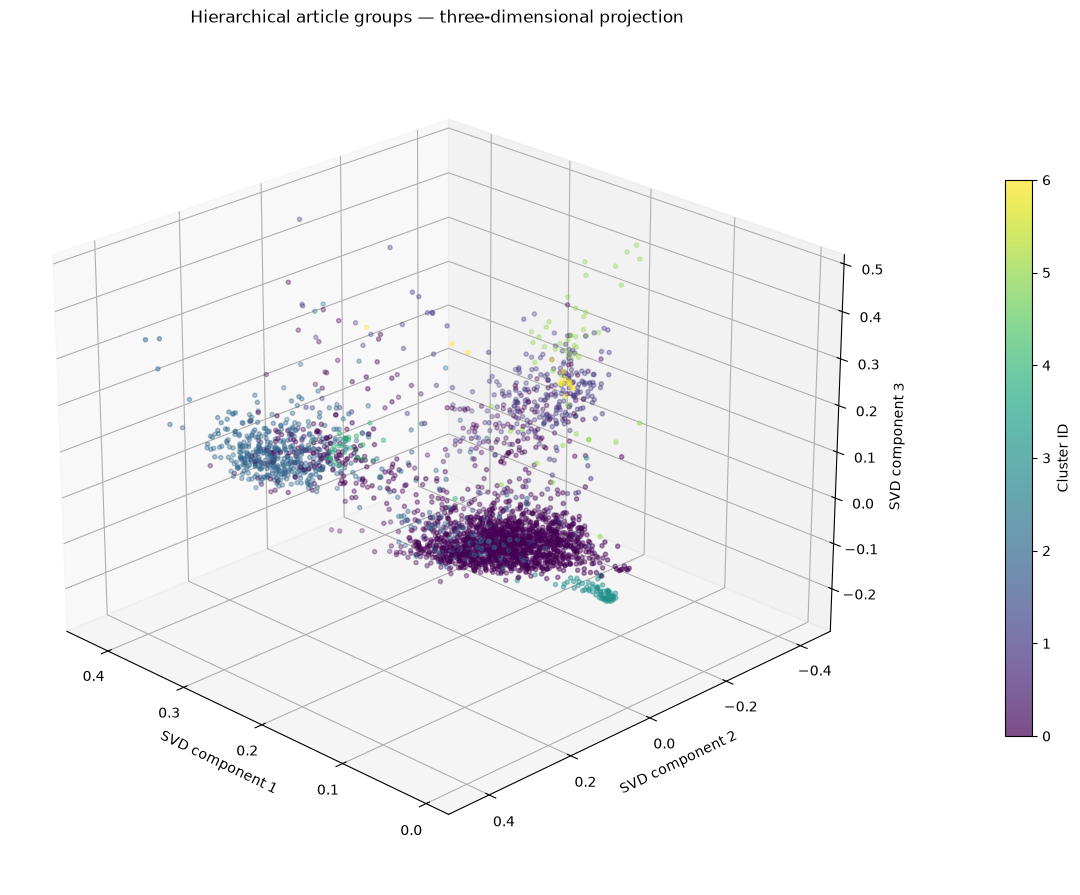

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# Preserve the original three-component projection and random seed.
svd = TruncatedSVD(n_components=3, random_state=43)
X_svd = svd.fit_transform(X_tfidf_matrix_normalized)

# Render the unchanged cluster assignments using Matplotlib rather than WebGL.
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')
points = ax.scatter(
    X_svd[:, 0], X_svd[:, 1], X_svd[:, 2],
    c=best_agg.labels_, cmap='viridis', s=9, alpha=0.7
)
ax.set_xlabel('SVD component 1')
ax.set_ylabel('SVD component 2')
ax.set_zlabel('SVD component 3')
ax.set_title('Hierarchical article groups — three-dimensional projection')
fig.colorbar(points, ax=ax, shrink=0.65, pad=0.12, label='Cluster ID')
ax.view_init(elev=24, azim=135)

# Save a static figure that displays inside VS Code without WebGL.
os.makedirs('./images', exist_ok=True)
fig.savefig('./images/agglomerative_clusters_3d.png', dpi=180, bbox_inches='tight')
plt.tight_layout()
plt.show()


**How to interpret this step.** A two-dimensional screenshot of this static 3D plot is only a projection of the original document geometry.


## Display leading terms for each cluster

Aggregate original TF-IDF weights for cluster members and chart the twenty highest-weight terms.



Plot successfully saved to: ./images/agglomerative_top_20_words_per_cluster.png


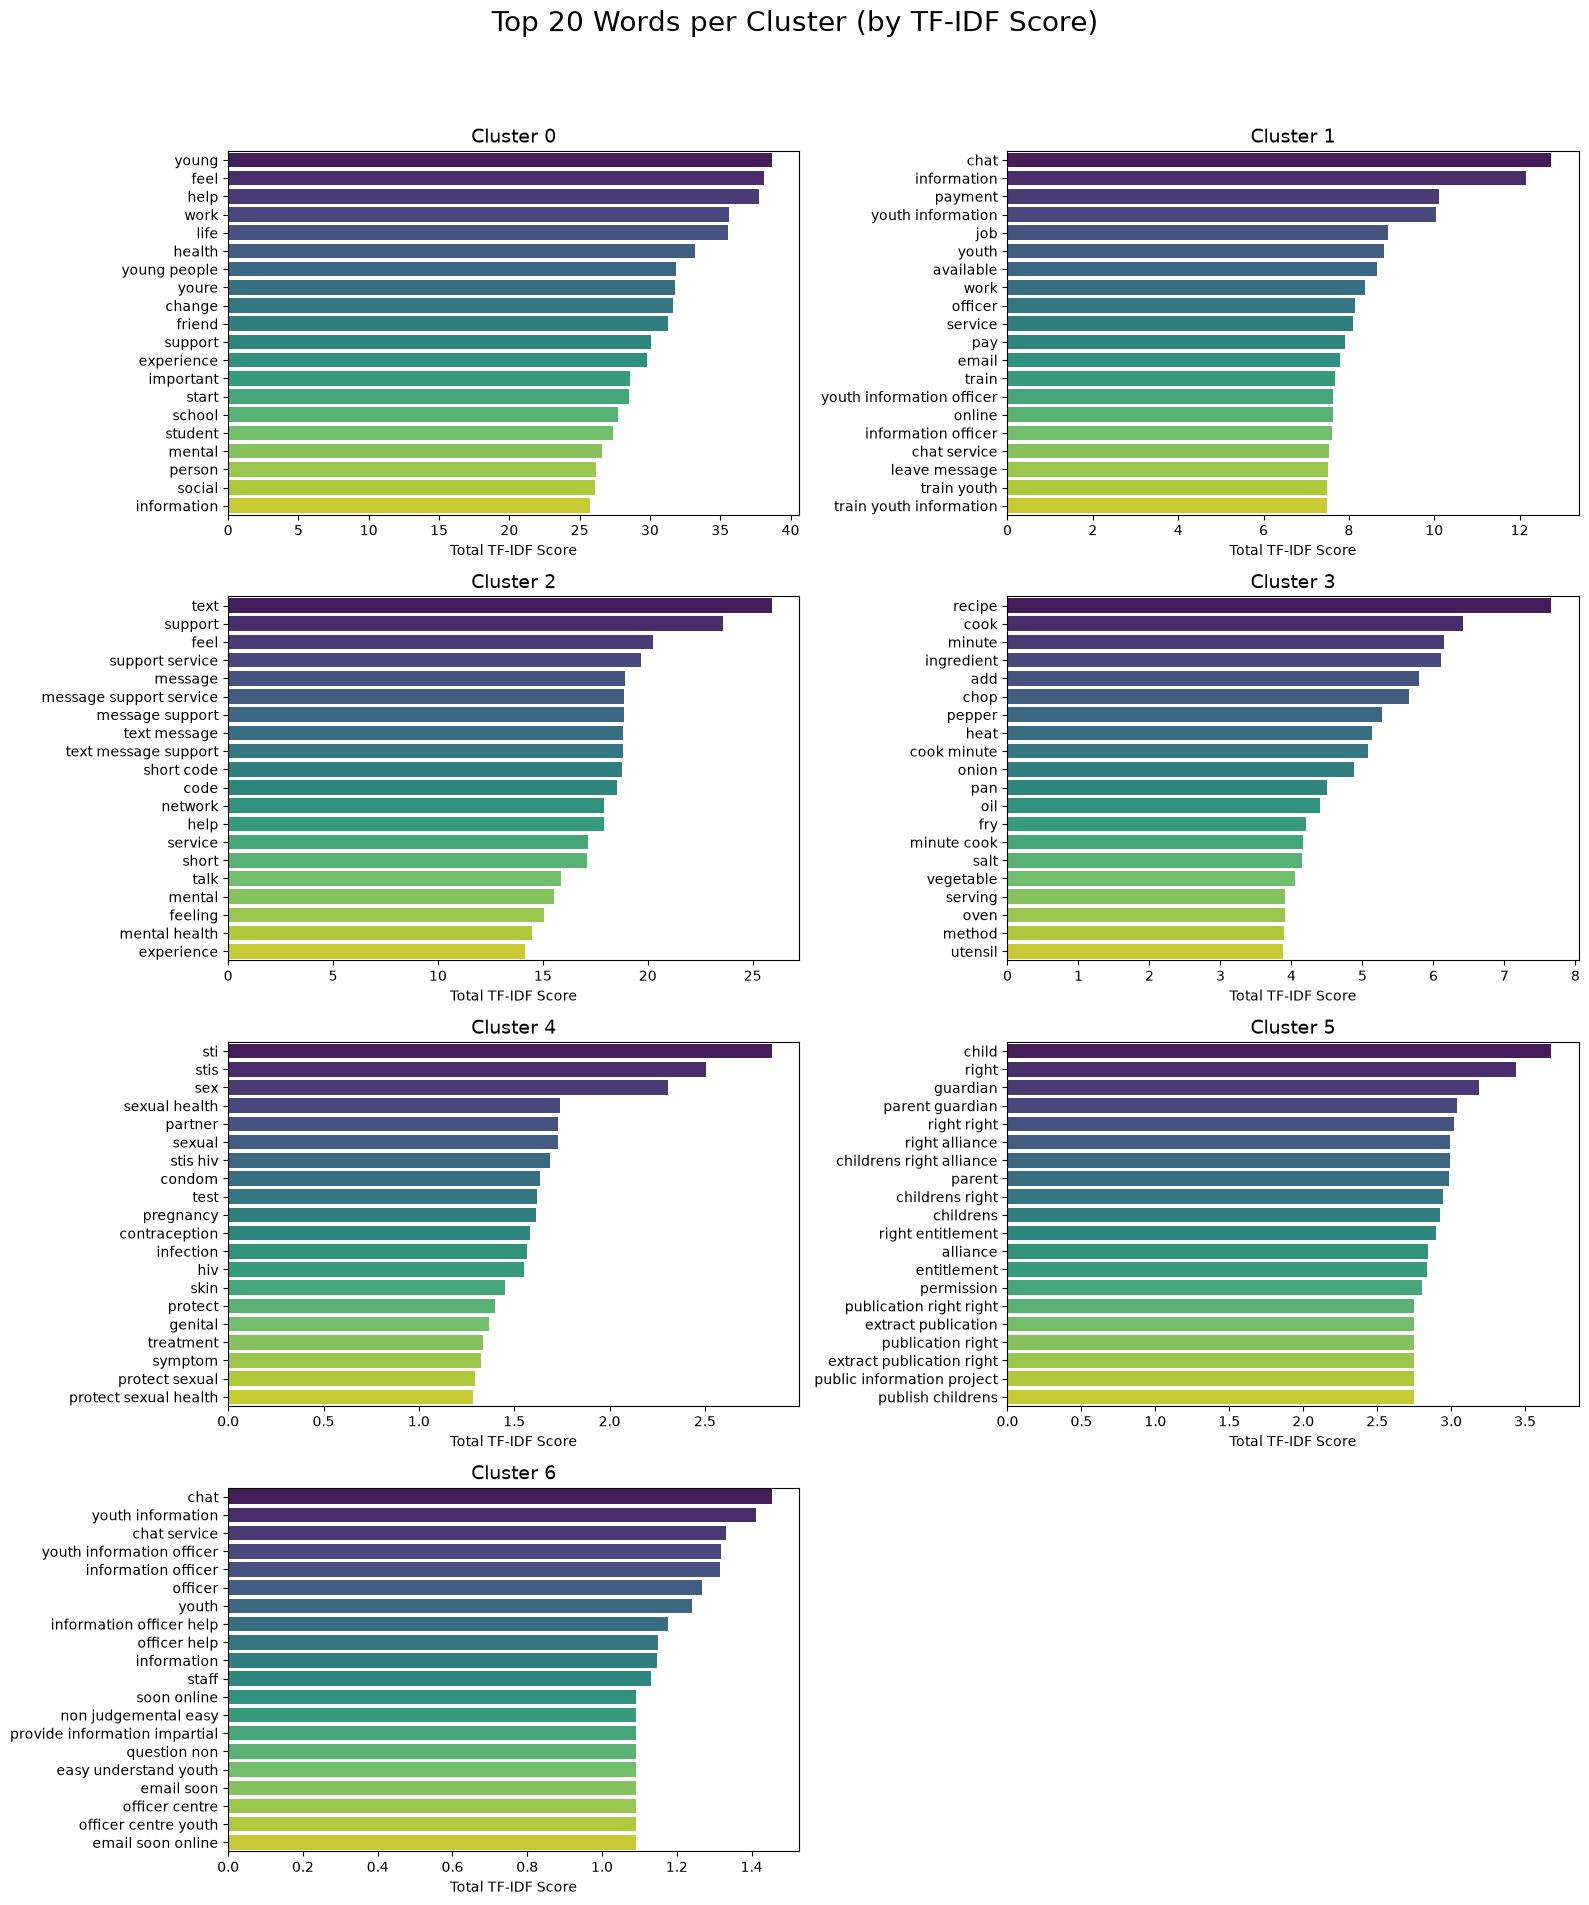

In [14]:
# Rank cluster vocabulary by accumulated TF-IDF weight.

import math


feature_names = tfidf_vectorizer.get_feature_names_out()


n_clusters = best_agg.n_clusters  


cols = 2
rows = math.ceil(n_clusters / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows))
fig.suptitle('Top 20 Words per Cluster (by TF-IDF Score)', fontsize=20)

axes = axes.flatten()

for i in range(n_clusters):
    
    cluster_indices = np.where(best_agg.labels_ == i)[0]
    
    
    cluster_tfidf = X_tfidf_matrix[cluster_indices]
    
    
    word_scores = np.array(cluster_tfidf.sum(axis=0)).flatten()
    
    
    top_indices = word_scores.argsort()[-20:][::-1]
    top_words = feature_names[top_indices]
    top_scores = word_scores[top_indices]
    
    
    df_plot = pd.DataFrame({"Word": top_words, "Score": top_scores})

    
    sns.barplot(ax=axes[i], data=df_plot, x='Score', y='Word', palette='viridis')
    axes[i].set_title(f'Cluster {i}', fontsize=14)
    axes[i].set_xlabel('Total TF-IDF Score')
    axes[i].set_ylabel('')


for j in range(n_clusters, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])


folder_name = "./images/"
file_name = "agglomerative_top_20_words_per_cluster.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

## Print cluster term summaries

Use a compact term list as evidence for provisional, human-readable cluster labels.


In [15]:
# Print a concise vocabulary summary for each hierarchical cluster.

print("Top Words per Cluster (by TF-IDF Score):")
print("-" * 40)

for i in range(n_clusters):
    
    cluster_indices = np.where(best_agg.labels_ == i)[0]
    cluster_tfidf = X_tfidf_matrix[cluster_indices]
    word_scores = np.array(cluster_tfidf.sum(axis=0)).flatten()
    top_indices = word_scores.argsort()[-20:][::-1]
    
    top_words = feature_names[top_indices]
    top_scores = word_scores[top_indices]
    
    
    print(f"\nCluster {i}:")
    
    print(", ".join(top_words))

Top Words per Cluster (by TF-IDF Score):
----------------------------------------

Cluster 0:
young, feel, help, work, life, health, young people, youre, change, friend, support, experience, important, start, school, student, mental, person, social, information

Cluster 1:
chat, information, payment, youth information, job, youth, available, work, officer, service, pay, email, train, youth information officer, online, information officer, chat service, leave message, train youth, train youth information

Cluster 2:
text, support, feel, support service, message, message support service, message support, text message, text message support, short code, code, network, help, service, short, talk, mental, feeling, mental health, experience

Cluster 3:
recipe, cook, minute, ingredient, add, chop, pepper, heat, cook minute, onion, pan, oil, fry, minute cook, salt, vegetable, serving, oven, method, utensil

Cluster 4:
sti, stis, sex, sexual health, partner, sexual, stis hiv, condom, test, pregn

## Compare cluster-centroid similarity

Build a cosine-similarity matrix of mean normalized document vectors.



Plot successfully saved to: ./images/agglomerative_inter_cluster_similarity.png


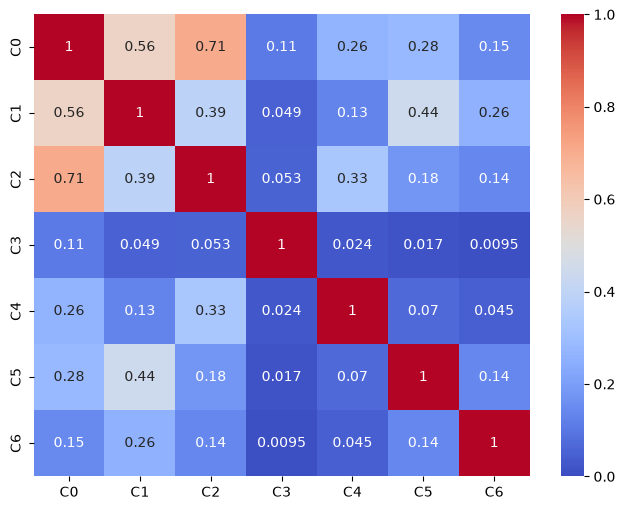

In [16]:
# Calculate pairwise cosine similarity of the cluster centroids.

from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns


centroids = []
for i in range(n_clusters):
    mask = (best_agg.labels_ == i)
    centroids.append(X_tfidf_matrix_normalized[mask].mean(axis=0))

centroids = np.array(centroids)


centroid_similarity = cosine_similarity(centroids)


plt.figure(figsize=(8, 6))
sns.heatmap(
    centroid_similarity, 
    annot=True, 
    cmap='coolwarm', 
    xticklabels=[f'C{i}' for i in range(n_clusters)],
    yticklabels=[f'C{i}' for i in range(n_clusters)],
    vmin=0, vmax=1
)



folder_name = "./images/"
file_name = "agglomerative_inter_cluster_similarity.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

**How to interpret this step.** The center similarity is a summary statistic and does not capture multimodal structure within a cluster.


## Inspect the similarity matrix numerically

Review rounded center similarities to complement the heatmap.


In [17]:
# Inspect the centroid-similarity values as a table.


cluster_labels = [f'Cluster {i}' for i in range(n_clusters)]



df_similarity = pd.DataFrame(
    centroid_similarity, 
    index=cluster_labels, 
    columns=cluster_labels
)


df_similarity = df_similarity.round(3)


print("\nInter-Cluster Similarity Matrix:")
print(df_similarity)


Inter-Cluster Similarity Matrix:
           Cluster 0  Cluster 1  Cluster 2  Cluster 3  Cluster 4  Cluster 5  \
Cluster 0      1.000      0.564      0.707      0.108      0.263      0.284   
Cluster 1      0.564      1.000      0.388      0.049      0.132      0.444   
Cluster 2      0.707      0.388      1.000      0.053      0.329      0.176   
Cluster 3      0.108      0.049      0.053      1.000      0.024      0.017   
Cluster 4      0.263      0.132      0.329      0.024      1.000      0.070   
Cluster 5      0.284      0.444      0.176      0.017      0.070      1.000   
Cluster 6      0.148      0.255      0.137      0.010      0.045      0.139   

           Cluster 6  
Cluster 0      0.148  
Cluster 1      0.255  
Cluster 2      0.137  
Cluster 3      0.010  
Cluster 4      0.045  
Cluster 5      0.139  
Cluster 6      1.000  


## Flag weakly associated articles

Report articles with unusually low similarity to their assigned centroid under the existing threshold.


In [18]:
# Review low-similarity documents as potential borderline cluster members.

print("Identifying potential Outliers (weakest links)...\n")

for i in range(n_clusters):
    cluster_mask = (best_agg.labels_ == i)
    cluster_docs = X_tfidf_matrix_normalized[cluster_mask]
    
    
    
    centroid = cluster_docs.mean(axis=0).reshape(1, -1)
    
    
    similarities = cosine_similarity(cluster_docs, centroid).flatten()
    
    
    worst_doc_local_index = similarities.argsort()[0]
    
    original_df_indices = np.where(best_agg.labels_ == i)[0]
    worst_original_index = original_df_indices[worst_doc_local_index]
    
    score = similarities[worst_doc_local_index]
    
    
    if score < 0.1: 
        title = df['article_title'].iloc[worst_original_index]
        print(f"CLUSTER {i} Outlier (Score: {score:.4f}):")
        print(f"  > {title}\n")

Identifying potential Outliers (weakest links)...

CLUSTER 0 Outlier (Score: 0.0175):
  > An bhfuil suim agat do thuairim, comhairle agus scéalta a roinnt?

CLUSTER 1 Outlier (Score: 0.0647):
  > Petition to Help End Youth Homelessness



**How to interpret this step.** These examples deserve manual review rather than automatic rejection.
